In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    print(root, len(files), files[:3])

/kaggle/input 0 []
/kaggle/input/datasets 0 []
/kaggle/input/datasets/felipekitamura 0 []
/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage 1 ['labels.csv']
/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage/head_ct 0 []
/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage/head_ct/head_ct 200 ['000.png', '001.png', '002.png']
/kaggle/input/notebooks 0 []
/kaggle/input/notebooks/felipekitamura 0 []


In [3]:
# Importing the libraries/dependencies
import pandas as pd, os
from PIL import Image
import matplotlib.pyplot as plt

['id', 'hemorrhage']
   id  hemorrhage
0   0           1
1   1           1
2   2           1
3   3           1
4   4           1
hemorrhage
1    100
0    100
Name: count, dtype: int64


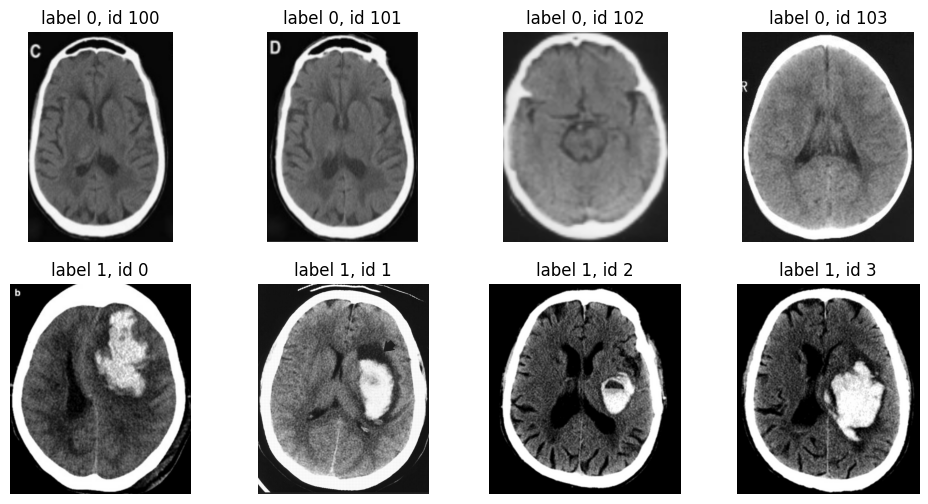

In [4]:
base = "/kaggle/input/datasets/felipekitamura/head-ct-hemorrhage"
folder = f"{base}/head_ct/head_ct"

df = pd.read_csv(f"{base}/labels.csv")
df.columns = [c.strip() for c in df.columns]
print(df.columns.tolist())
print(df.head())
label_col = df.columns[1]
print(df[label_col].value_counts())

def path_for(i):
    s = str(i)
    return f"{folder}/{s}" if s.endswith(".png") else f"{folder}/{int(i):03d}.png"

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, lab in enumerate([0, 1]):
    ids = df[df[label_col] == lab].iloc[:4, 0]
    for ax, i in zip(axes[row], ids):
        img = Image.open(path_for(i))
        ax.imshow(img, cmap="gray"); ax.set_title(f"label {lab}, id {i}"); ax.axis("off")
plt.show()

In [6]:
base = "/kaggle/input/datasets/ozguraslank/brain-stroke-ct-dataset/Brain_Stroke_CT_Dataset/External_Test"
t = pd.read_csv(f"{base}/labels.csv")
print(t.shape); print(t.head(10))
for c in t.columns[1:]:
    print(t[c].value_counts())

(200, 2)
   image_id  Stroke
0     10189       0
1     10200       0
2     10231       0
3     10267       0
4     10300       0
5     10301       0
6     10319       0
7     10360       0
8     10467       0
9     10493       0
Stroke
0    130
1     70
Name: count, dtype: int64
